# E17 · Training on Level-2A images of the EuroSAT patches

Every experiment so far tried to make Level-1C training images (with haze) look like the Level-2A Kaggle images
(atmospherically corrected): haze correction, Fourier methods, AdaBN, pseudo-labels. E17 removes the gap at its source:
`scripts/download_l2a.py` cuts the same 640 m × 640 m squares out of real **Level-2A** Sentinel-2 scenes (Microsoft
Planetary Computer, 2017–2018, growing season first, only patches that are cloud-free in the scene's own mask), so
training and test images come from the same processing.

**External data.** The competition rules do not forbid it; the download script is part of the code, so the
submission can be reproduced.

**Caveat.** The scene date is not the date of the original EuroSAT image (unknown), so some crops are at a different
stage, and a few patches may have changed land use. Section 2 shows samples.

Everything else is the **E09a setup**: EfficientNet-B0, 12 bands, contrast augmentation, round-3 pseudo-labels
(E06c + AdaBN teacher, 8 views agree, SeaLake capped at 400, used 2× per epoch). The change: Level-2A training images
instead of Level-1C + `hist_split` (no haze correction: there is no haze to correct). Validation and internal test
also use Level-2A, so their accuracy is not directly comparable with earlier runs.

**Before running:** `pip install pystac-client planetary-computer shapely`, then
`python scripts/download_l2a.py --limit 50` (test) and `python scripts/download_l2a.py` (all, resumable).

## 1 · Setup

In [9]:
import json
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS, load_split, load_test, load_train, load_train_l2a, train_metadata
from src.experiment import (add_pseudo_labels, class_mix, compare_variants, find_run, finish_run, kaggle_monitor,
                            kaggle_score, load_correction, load_experiment_data, load_saved_model, plot_class_mix,
                            plot_variant_curves, select_view_agree, teacher_predictions, view_agreement)
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import Normalizer, TrainConfig, fit, load_run, predict_views
from src.utils import describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E17_l2a_training"
LOAD_RUNS = {   # saved runs; None = train this variant again
    "E17a": None,
}
REFERENCE = "pl_r3_view_agree_contrast_aug_hist_split_effb0"               # E09a, no AdaBN, 72.67%
R3_TEACHER = "adabn_balanced_pseudo_label_r2_x2_contrast_aug_hist_split_effb0"   # E06c + AdaBN: round-3 labels
CAPS = {"SeaLake": 400}
REPEAT = 2
MODEL = "efficientnet_b0"
BANDS = list(TEST_BANDS)
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})   # as in E09a
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()
print("Device:", describe_device(device))
results = {}


def base_config(variant, run_name, description, extra):
    return {"run_name": run_name, "description": description, "notebook": NOTEBOOK, "variant": variant,
            "model": MODEL, "bands": BANDS, "corrections": [], "source": "l2a", "train": asdict(cfg),
            "split": "split_seed42", **extra}

Device: Apple GPU (MPS)


## 2 · How close are the Level-2A downloads to the Kaggle images?

Per-band median over images: EuroSAT Level-1C as it is, after `hist_split` (what E09a trained on), the downloaded
Level-2A images, and Kaggle. If the download worked, the Level-2A column should be close to Kaggle without any
correction. Then a few patches side by side (RGB): the label should still fit the Level-2A image.

In [10]:
X_l1c, _ = load_train()
X_l2a, ok = load_train_l2a()
X_kg, _ = load_test()
meta = train_metadata()
split = load_split()
print(f"Level-2A available: {ok.sum():,} of {len(ok):,} patches ({ok.mean():.1%})")
display(pd.Series(ok, index=meta["label"]).groupby(level=0).mean().reindex(CLASSES).mul(100).round(1)
        .rename("% with Level-2A").to_frame().T)

rng = np.random.default_rng(SEED)
sample = np.sort(rng.choice(np.flatnonzero(ok), 3000, replace=False))
l1c = np.asarray(X_l1c[sample])
hist = load_correction("hist_split")(l1c.copy())
l2a = np.asarray(X_l2a[sample])
kg = np.asarray(X_kg[rng.choice(len(X_kg), 3000, replace=False)])
med = lambda x: np.median(x.reshape(len(x), 12, -1).mean(2), axis=0)
pd.DataFrame({"EuroSAT L1C": med(l1c), "L1C + hist_split (E09a)": med(hist),
              "downloaded L2A (E17)": med(l2a), "Kaggle L2A": med(kg)}, index=TEST_BANDS).round(0)

Level-2A available: 26,902 of 27,000 patches (99.6%)


label,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
% with Level-2A,100.0,100.0,100.0,100.0,96.2,100.0,100.0,100.0,99.9,100.0


,EuroSAT L1C,L1C + hist_split (E09a),downloaded L2A (E17),Kaggle L2A
B01,1328.0,309.0,422.0,287.0
B02,1085.0,333.0,538.0,296.0
B03,998.0,614.0,785.0,555.0
B04,861.0,487.0,793.0,432.0
B05,1154.0,996.0,1221.0,905.0
B06,2077.0,2160.0,2126.0,1916.0
B07,2449.0,2479.0,2429.0,2186.0
B08,2379.0,2618.0,2536.0,2325.0
B8A,2699.0,2695.0,2650.0,2388.0
B09,713.0,2686.0,2668.0,2382.0


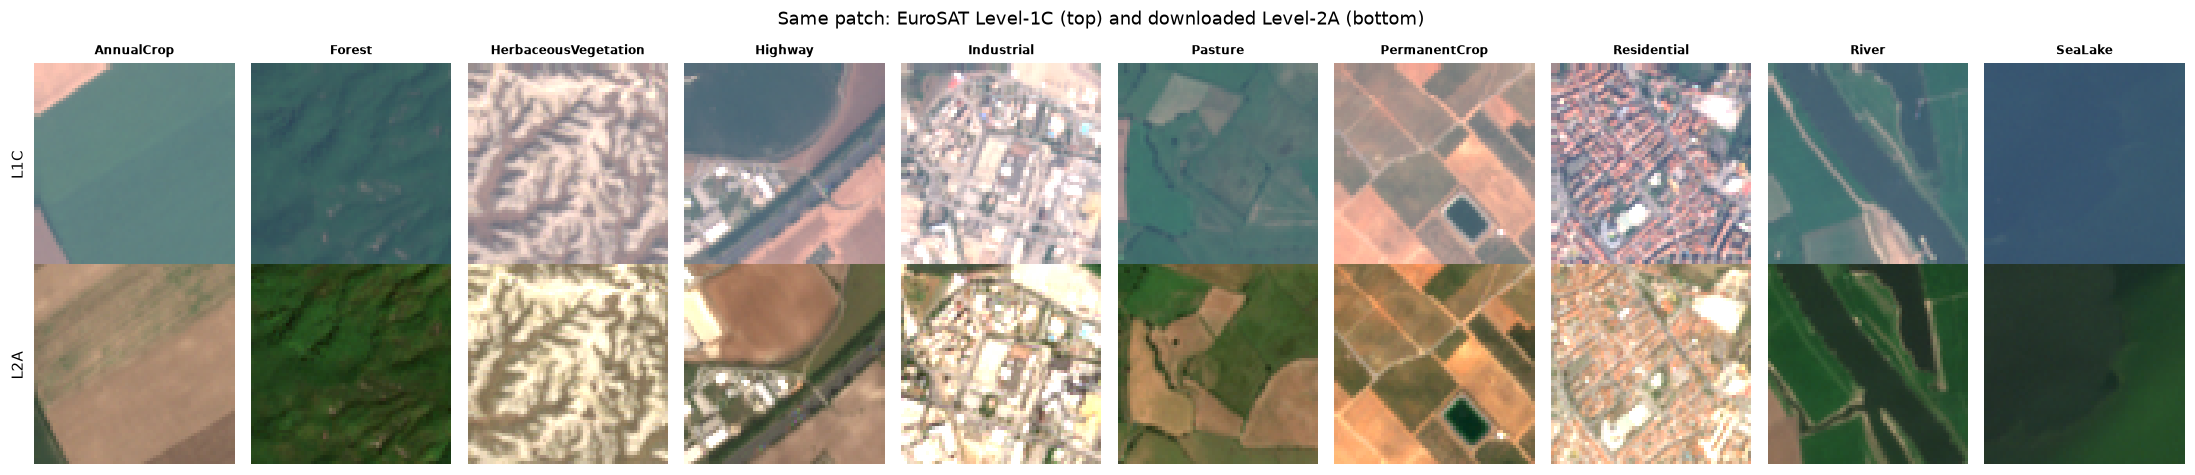

In [11]:
def rgb(x):
    img = x[[TEST_BANDS.index(b) for b in ["B04", "B03", "B02"]]].transpose(1, 2, 0).astype(np.float32)
    return np.clip(img / 2500, 0, 1) ** 0.8

show = [rng.choice(np.flatnonzero(ok & (meta["label"].values == c))) for c in CLASSES]
fig, axes = plt.subplots(2, len(CLASSES), figsize=(2 * len(CLASSES), 4.4))
for j, i in enumerate(show):
    axes[0, j].imshow(rgb(np.asarray(X_l1c[i]))); axes[0, j].set_title(CLASSES[j], fontsize=8)
    axes[1, j].imshow(rgb(np.asarray(X_l2a[i])))
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].text(-8, 32, "L1C", rotation=90, va="center"); axes[1, 0].text(-8, 32, "L2A", rotation=90, va="center")
fig.suptitle("Same patch: EuroSAT Level-1C (top) and downloaded Level-2A (bottom)")
plt.tight_layout()
del X_l1c, l1c, hist, l2a, kg

## 3 · Data and round-3 pseudo-labels (as in E09a)

In [12]:
data = load_experiment_data(BANDS, [], device, source="l2a")
print(data.summary())
table, _ = teacher_predictions(R3_TEACHER, data, device)   # Kaggle images only, same labels as E09a
hard_idx = select_view_agree(table, CAPS, SEED)
print(f"{len(hard_idx):,} pseudo-labels (E09a: 2,948)")

Level-2A training images: 26,902 of 27,000 patches
train 18,821  val 4,041  internal test 4,040  Kaggle test 4,232
2,948 pseudo-labels (E09a: 2,948)


## 4 · E17a · E09a setup on Level-2A training images

In [13]:
tr_images, tr_labels, _ = add_pseudo_labels(data, table, hard_idx, repeat=REPEAT)
if LOAD_RUNS["E17a"]:
    model, normalizer, history = load_saved_model(LOAD_RUNS["E17a"], device)
    best_state = None
else:
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    model = build_model(MODEL, bands=BANDS, pretrained=True).to(device)
    history, best_state = fit(model, tr_images, tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))

results["E17a"] = finish_run(model, normalizer, history, best_state, data, variant="E17a", load_run=LOAD_RUNS["E17a"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config=base_config("E17a", "l2a_pl_r3_view_agree_contrast_aug_effb0",
                       "E09a setup trained on downloaded Level-2A images of the EuroSAT patches (no hist_split)",
                       {"n_l2a_patches": int(data.X_tr.shape[0] + data.X_va.shape[0] + data.X_te.shape[0]),
                        "pseudo_labels": {"teacher": R3_TEACHER, "selection": "view_agree", "caps": CAPS,
                                          "repeat": REPEAT, "n_images": int(len(hard_idx))}}))
del tr_images, tr_labels

Pseudo-labelled Kaggle images: 2,948 of 4,232, used 2x (23.9% of the training set, 24,717 images)
epoch  1  train loss 1.516 acc 0.577  val loss 0.322 acc 0.925 *  val_conf 0.821  kg_conf 0.711  kg_sealake 0.246  kg_share_AnnualCrop 0.092  kg_share_Forest 0.132  kg_share_HerbaceousVegetation 0.101  kg_share_Highway 0.069  kg_share_Industrial 0.056  kg_share_Pasture 0.079  kg_share_PermanentCrop 0.078  kg_share_Residential 0.096  kg_share_River 0.050  kg_share_SeaLake 0.246  (50s)
epoch  2  train loss 0.752 acc 0.904  val loss 0.215 acc 0.955 *  val_conf 0.878  kg_conf 0.811  kg_sealake 0.241  kg_share_AnnualCrop 0.093  kg_share_Forest 0.090  kg_share_HerbaceousVegetation 0.116  kg_share_Highway 0.070  kg_share_Industrial 0.058  kg_share_Pasture 0.077  kg_share_PermanentCrop 0.102  kg_share_Residential 0.096  kg_share_River 0.059  kg_share_SeaLake 0.241  (45s)
epoch  3  train loss 0.672 acc 0.934  val loss 0.197 acc 0.958 *  val_conf 0.895  kg_conf 0.817  kg_sealake 0.242  kg_share_Annu

## 5 · Comparison with E09a

If the gap was the main problem, E17a should be **more confident and more stable on Kaggle** than E09a (confidence,
view agreement), and AdaBN should matter little. E17a's row is measured with AdaBN; E09a is given both ways.

In [14]:
ref_dir = find_run(REFERENCE)
r_model, r_norm, _ = load_run(ref_dir, device)
ref_views = predict_views(r_model, data.kg_images, r_norm)
ref_prob = ref_views.mean(0)
del r_model
summary = compare_variants(results, reference=ref_prob, reference_name="E09a")
r_metrics = json.loads((ref_dir / "metrics.json").read_text())
a_metrics = json.loads((find_run("adabn_balanced_" + REFERENCE) / "metrics.json").read_text())
summary.loc["E09a (no AdaBN)"] = pd.Series({"description": "best single model", "confidence (%)": ref_prob.max(1).mean() * 100,
                                            "view agreement (%)": view_agreement(ref_views) * 100,
                                            "same class as E09a (%)": 100.0, "Kaggle public (%)": kaggle_score(ref_dir)})
summary.loc["E09a (AdaBN)"] = pd.Series({"description": "best single model + AdaBN",
                                         "confidence (%)": a_metrics["kaggle_mean_confidence"] * 100,
                                         "view agreement (%)": a_metrics["kaggle_view_agreement"] * 100,
                                         "Kaggle public (%)": kaggle_score(find_run("adabn_balanced_" + REFERENCE))})
for k, r in results.items():
    summary.loc[k + " (no AdaBN)"] = pd.Series({"description": "no AdaBN", "confidence (%)": r.kg_prob.max(1).mean() * 100,
                                                "same class as E09a (%)": (r.kg_prob.argmax(1) == ref_prob.argmax(1)).mean() * 100,
                                                "Kaggle public (%)": kaggle_score(r.run_dir)})
summary.round(2)

,description,internal test (%),confidence (%),view agreement (%),same class as E09a (%),Kaggle public (%)
E17a,E09a setup trained on downloaded Level-2A imag...,97.673267,83.448959,88.327032,93.903592,None
E09a (no AdaBN),best single model,NaN,87.362061,90.500945,100.0,72.671
E09a (AdaBN),best single model + AdaBN,NaN,85.016817,88.657845,NaN,71.782
E17a (no AdaBN),no AdaBN,NaN,87.133942,NaN,94.305293,None


In [15]:
# Different predictions: E09a's class (rows) -> E17a's class, no AdaBN (columns)
ref_pred = np.array(CLASSES)[ref_prob.argmax(1)]
for k, r in results.items():
    new = np.array(CLASSES)[r.kg_prob.argmax(1)]
    changed = new != ref_pred
    print(f"{k}: {changed.sum()} images differ from E09a ({changed.mean():.1%})")
    display(pd.crosstab(ref_pred[changed], new[changed]).rename_axis(index="E09a", columns=k))

E17a: 241 images differ from E09a (5.7%)


E17a,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
E09a,,,,,,,,,,
AnnualCrop,0,2,0,2,1,5,12,0,3,0
Forest,1,0,7,0,0,10,0,0,2,0
HerbaceousVegetation,0,33,0,0,0,5,3,4,5,0
Highway,2,0,4,0,6,5,1,8,1,0
Industrial,0,0,2,1,0,0,2,14,1,0
Pasture,4,1,1,0,1,0,6,3,0,0
PermanentCrop,33,2,3,4,4,16,0,5,1,0
Residential,0,0,2,1,1,2,0,0,0,0
River,0,1,3,0,0,0,0,0,0,1


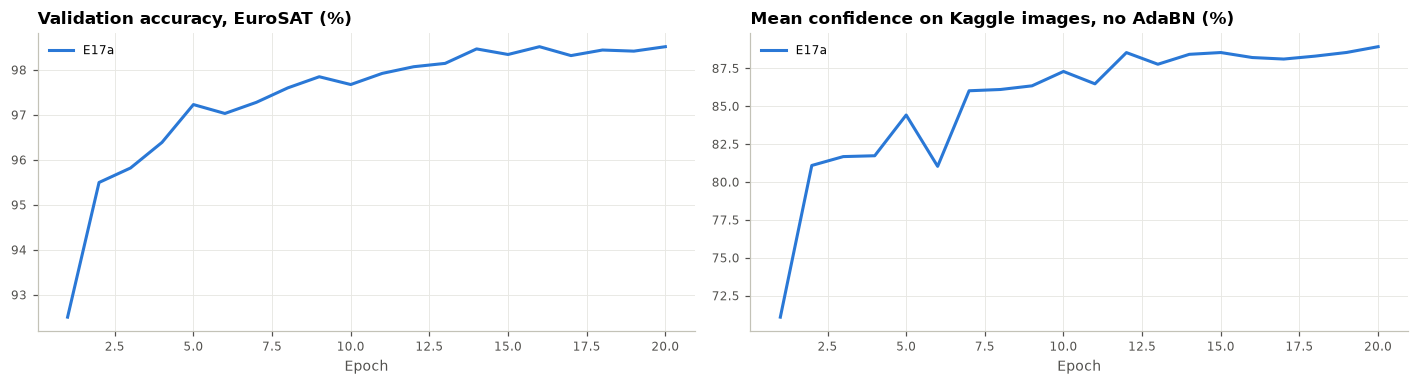

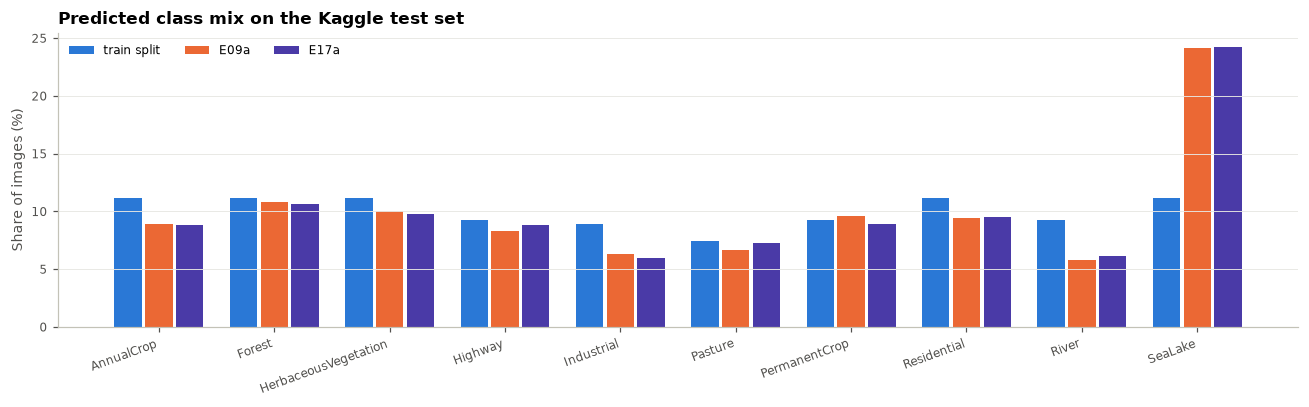

In [16]:
plot_variant_curves(results)
plot_class_mix(pd.DataFrame({"train split": class_mix(np.eye(10)[data.y_tr]), "E09a": class_mix(ref_prob),
                             **{k: class_mix(r.prob_ada) for k, r in results.items()}}))

## 6 · Conclusion

*To fill in after the Kaggle submission (both files: with and without AdaBN).*

| Model | Training images | Kaggle public (no AdaBN / AdaBN) |
|---|---|---|
| E09a | EuroSAT L1C + hist_split | 72.67% / 71.78% |
| E15a | ensemble | **72.81%** |
| E17a | downloaded L2A | |

Next if it helps: pseudo-labels from E17a, and E17a as an ensemble member (it should make very different mistakes).